In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv(
    "/content/dataset.csv",
    encoding="utf-8-sig"
)

print("Dataset loaded successfully!")

print("\nFirst five records:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset shape:")
print(df.shape)

Dataset loaded successfully!

First five records:
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch

Column names:
['Text', 'language']

Dataset shape:
(22000, 2)


In [ ]:
df.columns = df.columns.str.strip()

df = df[["Text", "language"]].copy()

df = df.dropna()

df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["Text"] != "") &
    (df["language"] != "")
]

df = df.drop_duplicates(
    subset=["Text", "language"]
)

print("Dataset prepared successfully!")

print("\nTotal records:", len(df))

print("\nNumber of languages:",
      df["language"].nunique())

print("\nLanguage distribution:")
print(df["language"].value_counts())

Dataset prepared successfully!

Total records: 21858

Number of languages: 22

Language distribution:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [ ]:
X = df["Text"]
y = df["language"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Data splitting completed!
Training records: 17486
Testing records: 4372


In [ ]:
features = FeatureUnion([
    (
        "word",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            sublinear_tf=True
        )
    ),
    (
        "character",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            sublinear_tf=True
        )
    )
])

model = Pipeline([
    ("features", features),
    ("classifier", LinearSVC(C=1.0))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("=" * 45)
print("LANGUAGE IDENTIFICATION MODEL")
print("=" * 45)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

LANGUAGE IDENTIFICATION MODEL
Test Accuracy: 98.72%

Classification Report:
              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00       200
     Chinese       0.99      0.99      0.99       200
       Dutch       0.99      1.00      1.00       199
     English       0.83      1.00      0.90       200
    Estonian       0.99      0.98      0.99       200
      French       0.99      1.00      1.00       198
       Hindi       1.00      0.96      0.98       198
  Indonesian       1.00      0.99      0.99       195
    Japanese       1.00      1.00      1.00       200
      Korean       1.00      0.99      0.99       200
       Latin       0.97      0.97      0.97       191
     Persian       1.00      0.99      0.99       200
   Portugese       0.99      0.99      0.99       199
      Pushto       1.00      0.94      0.97       199
    Romanian       1.00      0.99      0.99       200
     Russian       0.99      0.98      0.99       200
     

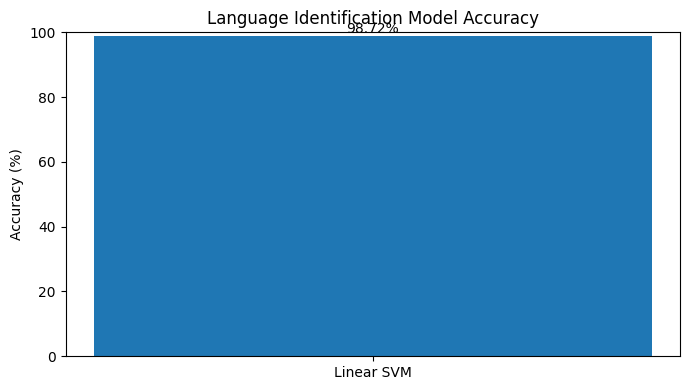

In [ ]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Linear SVM"],
    [accuracy * 100]
)

plt.title("Language Identification Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.text(
    0,
    accuracy * 100 + 1,
    f"{accuracy * 100:.2f}%",
    ha="center"
)

plt.tight_layout()
plt.show()

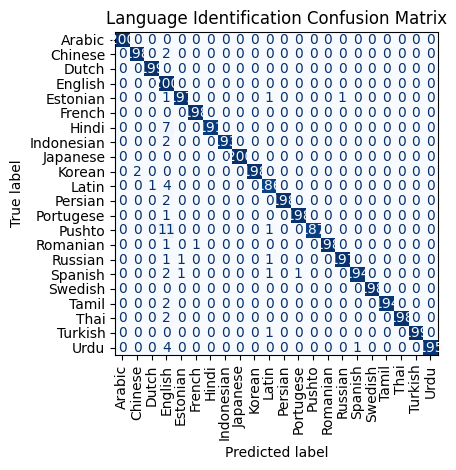

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=False
)

plt.title("Language Identification Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print("Available languages:")
print(df["language"].value_counts())

print("\nEnglish sample messages:")
print(df[df["language"] == "English"]["Text"].head(10))

print("\nChinese sample messages:")
print(df[df["language"] == "Chinese"]["Text"].head(10))

Available languages:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64

English sample messages:
37     in  johnson was awarded an american institute ...
40     bussy-saint-georges has built its identity on ...
76     minnesotas state parks are spread across the s...
90     nordahl road is a station served by north coun...
97     a talk by takis fotopoulos about the internati...
107    while running a campaign to elect his sister s...
127    reynolds was born in wiesbaden germany where h...
155    since the days of the revolution a one-room st...
156    obreption and subreption both from th

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

X = df["Text"].astype(str)
y = df["language"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

features = FeatureUnion([
    ("word", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("char", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        sublinear_tf=True
    ))
])

model = Pipeline([
    ("features", features),
    ("classifier", LinearSVC(C=1.0))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model retrained successfully!")
print("Accuracy:",
      round(accuracy_score(y_test, predictions) * 100, 2), "%")

Model retrained successfully!
Accuracy: 98.72 %


In [ ]:
test_sentences = [
    "Hello, how are you?",
    "This is my college project",
    "I am studying computer science",
    "Bonjour tout le monde",
    "Hola, buenos dias",
    "Guten Morgen"
]

for sentence in test_sentences:
    prediction = model.predict([sentence])[0]
    print(sentence, " --> ", prediction)

Hello, how are you?  -->  Chinese
This is my college project  -->  English
I am studying computer science  -->  Chinese
Bonjour tout le monde  -->  French
Hola, buenos dias  -->  Chinese
Guten Morgen  -->  Chinese


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Load dataset freshly
df = pd.read_csv("/content/dataset.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

# 2. Check required columns
print("Dataset columns:", df.columns.tolist())

if not {"Text", "language"}.issubset(df.columns):
    raise ValueError("Dataset must contain Text and language columns.")

# 3. Clean dataset
df = df[["Text", "language"]].dropna().copy()
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()
df = df[(df["Text"] != "") & (df["language"] != "")]
df = df.drop_duplicates()

print("\nTotal records:", len(df))
print("Number of languages:", df["language"].nunique())
print("\nLanguage counts:")
print(df["language"].value_counts())

# 4. Split data
X_train, X_test, y_train, y_test = train_test_split(
    df["Text"],
    df["language"],
    test_size=0.20,
    random_state=42,
    stratify=df["language"]
)

# 5. Train a fresh model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(1, 5),
        sublinear_tf=True,
        max_features=200000
    )),
    ("classifier", LinearSVC(C=1.0))
])

model.fit(X_train, y_train)

# 6. Evaluate
y_pred = model.predict(X_test)

print("\nTest accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 7. Inspect actual training samples
print("\nEnglish training samples:")
print(X_train[y_train == "English"].head(10).to_list())

# 8. Test different sentences
test_sentences = [
    "Hello, how are you?",
    "This is my college project",
    "I am studying computer science",
    "Bonjour tout le monde",
    "Hola buenos dias",
    "Guten Morgen"
]

print("\nTEST PREDICTIONS")
for sentence in test_sentences:
    print(sentence, " --> ", model.predict([sentence])[0])

Dataset columns: ['Text', 'language']

Total records: 21858
Number of languages: 22

Language counts:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64

Test accuracy: 98.67 %

Classification report:
              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00       200
     Chinese       0.99      0.99      0.99       200
       Dutch       0.99      1.00      1.00       199
     English       0.83      1.00      0.90       200
    Estonian       0.99      0.99      0.99       200
      French       0.99      1.00      0.99       198
       Hindi      

In [ ]:
!pip install -q fasttext

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!wget -q https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.ftz -O /content/lid.176.ftz

In [ ]:
!pip install -q langid

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 10.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:

import langid

tests = [
    "Hello, how are you?",
    "Bonjour tout le monde",
    "Hola buenos dias",
    "Guten Morgen",
    "வணக்கம்"
]

for sentence in tests:
    language, score = langid.classify(sentence)
    print(sentence, "->", language)


Hello, how are you? -> en
Bonjour tout le monde -> fr
Hola buenos dias -> es
Guten Morgen -> de
வணக்கம் -> ta


In [ ]:
!pip install -q langid

In [ ]:

import langid

def identify_language():
    text = input("Enter a sentence: ").strip()

    if not text:
        print("Please enter a sentence.")
        return

    language_codes = {
        "en": "English",
        "ta": "Tamil",
        "fr": "French",
        "es": "Spanish",
        "de": "German",
        "hi": "Hindi",
        "te": "Telugu",
        "ml": "Malayalam",
        "kn": "Kannada",
        "zh": "Chinese",
        "ja": "Japanese",
        "ko": "Korean",
        "ar": "Arabic"
    }

    code, score = langid.classify(text)
    language = language_codes.get(code, code.upper())

    print("Input Text:", text)
    print("Predicted Language:", language)

identify_language()


Enter a sentence: My name is elakkiya
Input Text: My name is elakkiya
Predicted Language: English


In [ ]:
import langid

def identify_language():
    text = input("Enter a sentence: ").strip()

    if not text:
        print("Please enter a sentence.")
        return

    language_codes = {
        "en": "English",
        "ta": "Tamil",
        "fr": "French",
        "es": "Spanish",
        "de": "German",
        "hi": "Hindi",
        "te": "Telugu",
        "ml": "Malayalam",
        "kn": "Kannada",
        "zh": "Chinese",
        "ja": "Japanese",
        "ko": "Korean",
        "ar": "Arabic"
    }

    code, score = langid.classify(text)
    language = language_codes.get(code, code.upper())

    print("Input Text:", text)
    print("Predicted Language:", language)

identify_language()


Enter a sentence: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Input Text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted Language: Tamil


In [ ]:
import langid

def identify_language():
    text = input("Enter a sentence: ").strip()

    if not text:
        print("Please enter a sentence.")
        return

    language_codes = {
        "en": "English",
        "ta": "Tamil",
        "fr": "French",
        "es": "Spanish",
        "de": "German",
        "hi": "Hindi",
        "te": "Telugu",
        "ml": "Malayalam",
        "kn": "Kannada",
        "zh": "Chinese",
        "ja": "Japanese",
        "ko": "Korean",
        "ar": "Arabic"
    }

    code, score = langid.classify(text)
    language = language_codes.get(code, code.upper())

    print("Input Text:", text)
    print("Predicted Language:", language)

identify_language()

Enter a sentence: Bonjour tout le monde
Input Text: Bonjour tout le monde
Predicted Language: French


In [ ]:
import langid

def identify_language():
    text = input("Enter a sentence: ").strip()

    if not text:
        print("Please enter a sentence.")
        return

    language_codes = {
        "en": "English",
        "ta": "Tamil",
        "fr": "French",
        "es": "Spanish",
        "de": "German",
        "hi": "Hindi",
        "te": "Telugu",
        "ml": "Malayalam",
        "kn": "Kannada",
        "zh": "Chinese",
        "ja": "Japanese",
        "ko": "Korean",
        "ar": "Arabic"
    }

    code, score = langid.classify(text)
    language = language_codes.get(code, code.upper())

    print("Input Text:", text)
    print("Predicted Language:", language)

identify_language()

Enter a sentence: Once upon a time there is a girl named elakkiya
Input Text: Once upon a time there is a girl named elakkiya
Predicted Language: English


In [ ]:
import langid

def identify_language():
    text = input("Enter a sentence: ").strip()

    if not text:
        print("Please enter a sentence.")
        return

    language_codes = {
        "en": "English",
        "ta": "Tamil",
        "fr": "French",
        "es": "Spanish",
        "de": "German",
        "hi": "Hindi",
        "te": "Telugu",
        "ml": "Malayalam",
        "kn": "Kannada",
        "zh": "Chinese",
        "ja": "Japanese",
        "ko": "Korean",
        "ar": "Arabic"
    }

    code, score = langid.classify(text)
    language = language_codes.get(code, code.upper())

    print("Input Text:", text)
    print("Predicted Language:", language)

identify_language()

Enter a sentence: hiii how aree u??are u angry??
Input Text: hiii how aree u??are u angry??
Predicted Language: English


In [ ]:
!pip install -q scikit-learn pandas

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
df = pd.read_csv("/content/dataset.csv")

# Keep required columns and remove missing values
df = df[["Text", "language"]].dropna()
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()
df = df[df["Text"] != ""]

# Input text and correct language labels
X = df["Text"]
y = df["language"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create and train model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(1, 5),
        sublinear_tf=True
    )),
    ("classifier", LinearSVC())
])

model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Language Identification Model")
print("-----------------------------")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Language Identification Model
-----------------------------
Training samples: 17599
Testing samples: 4400
Test Accuracy: 98.82%

Classification Report:
              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00       200
     Chinese       0.99      0.99      0.99       200
       Dutch       1.00      1.00      1.00       200
     English       0.85      1.00      0.92       200
    Estonian       0.99      0.99      0.99       200
      French       0.98      0.99      0.99       200
       Hindi       1.00      0.98      0.99       200
  Indonesian       1.00      0.97      0.99       200
    Japanese       1.00      0.99      1.00       200
      Korean       1.00      0.99      0.99       200
       Latin       0.98      0.96      0.97       200
     Persian       1.00      0.99      0.99       200
   Portugese       0.98      0.98      0.98       200
      Pushto       1.00      0.96      0.98       200
    Romanian       1.00      0.98    

In [ ]:
while True:
    text = input("Enter a sentence (or type exit): ").strip()

    if text.lower() == "exit":
        print("Program stopped.")
        break

    if not text:
        print("Please enter a sentence.")
        continue

    prediction = model.predict([text])[0]
    print("Predicted Language:", prediction)
    print("-" * 30)

Enter a sentence (or type exit): Hello how are you


ValueError: Unrecognized data type: x=['Hello how are you'] (of type <class 'list'>)

In [ ]:
!pip install -q pandas scikit-learn

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
df = pd.read_csv("/content/dataset.csv")

# Clean dataset
df = df[["Text", "language"]].dropna()
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()
df = df[df["Text"] != ""]

# Remove classes with fewer than 2 samples
counts = df["language"].value_counts()
df = df[df["language"].isin(counts[counts >= 2].index)]

X = df["Text"]
y = df["language"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Create model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(1, 5),
        sublinear_tf=True
    )),
    ("classifier", LinearSVC())
])

# Train model
model.fit(X_train, y_train)

# Calculate test accuracy
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))



Test Accuracy: 98.82%

Classification Report:
              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00       200
     Chinese       0.99      0.99      0.99       200
       Dutch       1.00      1.00      1.00       200
     English       0.85      1.00      0.92       200
    Estonian       0.99      0.99      0.99       200
      French       0.98      0.99      0.99       200
       Hindi       1.00      0.98      0.99       200
  Indonesian       1.00      0.97      0.99       200
    Japanese       1.00      0.99      1.00       200
      Korean       1.00      0.99      0.99       200
       Latin       0.98      0.96      0.97       200
     Persian       1.00      0.99      0.99       200
   Portugese       0.98      0.98      0.98       200
      Pushto       1.00      0.96      0.98       200
    Romanian       1.00      0.98      0.99       200
     Russian       0.99      0.99      0.99       200
     Spanish       0.99      0.98  

In [30]:

while True:
    text = input("Enter a sentence (or type exit): ").strip()

    if text.lower() == "exit":
        print("Program stopped.")
        break

    if not text:
        print("Please enter a sentence.")
        continue

    prediction = model.predict([text])[0]
    print("Predicted Language:", prediction)
    print("-" * 30)


Enter a sentence (or type exit): HAI ELAKKIYA HOW ARE YOU
Predicted Language: Turkish
------------------------------
Enter a sentence (or type exit): hello how are you
Predicted Language: English
------------------------------
Enter a sentence (or type exit): How are you
Predicted Language: English
------------------------------
Enter a sentence (or type exit): exit
Program stopped.
